### **White Dwarf Mass-Radius Relation Under Various Equations of State**

#### **Background**

At the end of a Sun-like star's life, after the layers of the Red Giant has been dispersed into a planetary nebula, the stellar core remains with the mass of the Sun and radius similar to Earth known as a white dwarf. They have extreme densities on the order of about 200,000 times denser than Earth. Instead of being supported by gas and radiation pressure unlike a main-sequence star, electron degeneracy pressure is the dominant term which stems from electrons being packed due to gravity leading to the Pauli Exclusion Principle preventing the electrons from occupying the same energy level. 

We can mathematically model the interior to that of a zero-temperature Fermi gas by parametrizing the Pressure P and density $\rho$ by the variable $\large x \equiv \frac{p_F}{m_e c}$ (Ratio of the fermi momentum to $m_e c$):

$$P = A (x(2x^2 - 3)(1 + x^2)^{1/2} + 3 \sinh^{-1}(x))$$

$$\frac{\rho}{\mu_e} = Bx^3$$

Where 

$$A = \frac{\pi}{3} \left( \frac{h}{m_e c} \right)^{-3} m_e c^2$$

$$B = \frac{8\pi m_p}{3} \left(\frac{h}{m_e c}\right)^{-3}$$

and $\mu_e \equiv \frac{\left(\frac{\rho}{m_p}\right)}{n_e}$ is the electronic molecular weight. We assume the white dwarf is composed primarily of carbon-oxygen then $\mu_e \approx 2$.


In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp
from scipy import integrate
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from numba import njit
from scipy.interpolate import make_interp_spline

In [2]:
G = 6.673 * 10**-11
c = 3 * 10**8
h = 6.626 * 10**-34
hbar = h/(2 * np.pi)
ep_0 = 8.854 * 10**-12
q = 1.602 * 10**-19
k_e = 1/(4 * np.pi * ep_0)
k_b = 1.3806 * 10**-23
Mp = 1.673 * 10**-27
Me = 9.109 * 10**-31
mu_e = 2
A = np.pi/3 * (h/(Me * c))**(-3) * Me * c**2
B = 8 * np.pi * Mp/3 * (h/(Me * c))**(-3)
Msol= 1.989 * 10**30
Re = 6378 * 10**3


### **Electron Degenerate, Newtonian White Dwarfs**

To a very good approximation, white dwarfs can be treated as objects under Newtonian gravity. The Fermi gas equation of state is used in the hydrostatic equilibrium equation where gravitational force balances the degeneracy pressure gradient.

$$\frac{1}{r^2} \frac{d}{dr} \left( \frac{r^2}{\rho} \frac{dP}{dr} \right) = - 4\pi G \rho $$

Redefining the variable x and applying the chain rule, we can rescale the variables

$$z^2 \equiv x^2 +1$$

$$Q \equiv \frac{z}{z_c}$$

$$\zeta \equiv \frac{r}{\alpha}$$

$$\alpha = \sqrt\frac{2 A}{\pi G}\left(\frac{1}{B \mu_e z_c}\right)$$

Where $z_c$ is the value of z at the center of the star.

The mathematical details are not included but we get the following ordinary differential equation for zero-temperature fermi gas under hydrostatic equilibrium.

$$\frac{d^2 Q}{d \zeta^2} + \frac{2}{\zeta} \frac{dQ}{d \zeta} + \left(Q^2 - \frac{1}{z_c^2}\right)^{3/2} = 0$$

The boundary conditions at the origin are 

$$ Q(0) = 1  \hspace{1cm} Q'(0) = 0 $$

This follows from the fact that the gradient has to vanish at the origin and definition of Q implies at Q(0) = 1 at the center.

The density at any location within the star is:

$$\rho = B \mu_e x^3 = B \mu_e (z^2 - 1)^{3/2} = B \mu_e z_c^3 \left(Q^2 - \frac{1}{z_c^2}\right)^{3/2}$$

The point at which the density is zero at say $\zeta = \zeta_1$ corresponds to the radius of the star. Then the boundary conditions at the surface are

$$x_1 = 0 \hspace{1cm} z_1 = 1 \hspace{1cm} Q_1 = \frac{1}{z_c} $$

Subscript of 1 indicates values at the surface.

Then the radius of the star R is,

$$R = \alpha \zeta_1$$

and the total mass M of the white dwarf (after integration from 0 to $Q_1$) is

$$M = \frac{4\pi}{(B \mu_e)^2} \left(\frac{2A}{\pi G}\right)^{3/2}\left(- \zeta^2 \frac{dQ}{d \zeta}\right)_1

#### **Generating a Mass-Radius Relation Curve**

The ODE governing the internal structure can be solved numerically for a given initial condition in Q and Q' however we run into a singularity if integrated from the origin itself ($\zeta = 0$)

Hence, we can expand $Q(\zeta)$ and $Q'(\zeta)$ in a Taylor series centered at $\zeta = 0$. Then the ODE can be integrated until we find the surface and compute the mass.

By solving the ODE for an array of initial conditions of $x_c$ and computing the mass and radius for each iteration and storing them. They can be plotted as Mass-Radius Curve. A sensible range of central densities are chosen and the plot appears as follows.

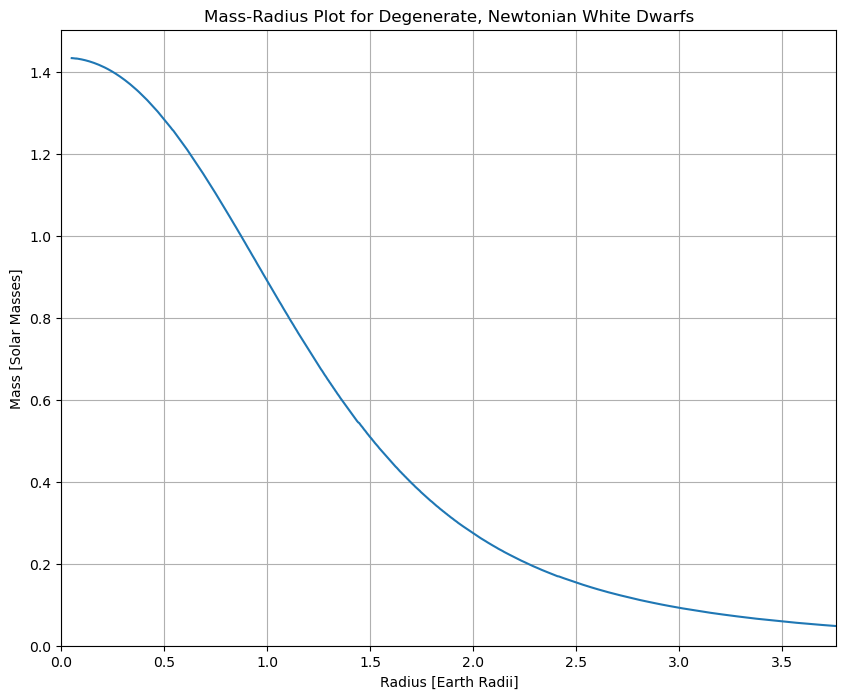

In [3]:
rho_arr = np.logspace(7, 15, 10**3)    #Range of central densities in kg/m^3
xc_arr = (rho_arr/(mu_e * B))**(1/3)   #Calculated central x
yc_arr = np.sqrt(xc_arr**2 + 1) 
alpha_arr = np.sqrt(2 * A/(np.pi * G)) * (1/(B * mu_e * yc_arr)) 


z_span = (0.001, 20)
z_eval = np.linspace(0.001, 20, 10**4)

@njit

def newt_WD(z, w, y_c):  #Instead of zeta, z has been chosen.
    Q, dQdz = w
    d2Qdz2 = -(2/z) * dQdz - (Q**2 - 1/y_c**2)**(3/2)
    return [dQdz, d2Qdz2]

def surface(z, w, y_c):  #Defined surface event where Q = 1/y_c
        Q = w[0]
        return Q - 1/y_c

surface.terminal = True 
surface.direction = -1   #Shows that we are looking for decreasing Q


def MR_relation_NWD(): 
    M_newtWD = []
    R_newtWD = []
    z1 = 0.001  #Begins integration close to the center at z = 0.001 which avoids singularities.
    Q1_arr = 1 - 1/6 * (1 - 1/yc_arr**2)**(3/2) * z1**2  #Taylor expansion to approximate Q and Q' at z = 0.001
    dQdz1_arr = -1/3 * (1 - 1/yc_arr**2)**(3/2) * z1
    np.seterr(invalid='ignore')
    for i in range(len(rho_arr)):
        y0 = [Q1_arr[i], dQdz1_arr[i]]
        sol = solve_ivp(newt_WD, z_span, y0, events=surface, t_eval=z_eval, args=(yc_arr[i],))
        z_s = sol.t[-1]
        dQdz_s = sol.y[1][-1]
        R = alpha_arr[i] * z_s
        M = 4 * np.pi/(B * mu_e)**2 * (2 * A/(np.pi * G))**(3/2) * (-z_s**2 * dQdz_s)
        M_newtWD.append(M/Msol)   #Computes mass and radius for each central density
        R_newtWD.append(R/Re)

    return [R_newtWD, M_newtWD]

R_NWD, M_NWD = MR_relation_NWD()

plt.figure(figsize=(10,8))
plt.plot(R_NWD, M_NWD)
plt.title('Mass-Radius Plot for Degenerate, Newtonian White Dwarfs')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD))
plt.ylim(bottom=0)
plt.grid()


The curve shows a decrease in radius leading to a greater mass of the star which is expected of electron degenerate matter. The greater the mass, the more electrons have to pack together in a smaller volume to counteract the effect of more gravitational force. 

The mass appears to peak at about $\sim 1.4 M_{\odot}$ which is close to the Chandrasekhar limit, the maximum mass possible for a white dwarf.

### **Coloumb Corrections**

The second most dominant term is the coloumb interactions between ions closer to the surface of the star where densities are lower. The leads to pressure term which reduces the pressure exerted by the fermi gas. To calculate this, we model the ions as being separated into a lattice structure where there is a +Ze ion charge at the center and Z electrons distributed uniformly in a sphere of radius $r_0$. An average of Z will be calculated using the assumption that 50-50 of the star's mass comes from the carbon and oxygen. We can compute the total electrostatic energy $E_c$ of that configuration.

The repulsive electrostatic energy between the electrons in the cell is,

$$E_{ee} = \frac{3}{5} k \frac{Z^2 e^2}{r_0}$$

and the attractive energy between the nucleus and the electrons is,

$$E_{ei} = - \frac{3}{2} k \frac{Z^2 e^2}{r_0}$$

Summing these two gives the total electrostatic energy of the cell,

$$E_c = E_{ee} + E_{ei} = -\frac{9}{10} k \frac{Z^2 e^2}{r_0} $$

Then we can define the electrostatic energy per electron 

$$\epsilon \equiv \frac{E_c}{Z}$$

and the electron number density $\large n_e = \frac{3Z}{4 \pi r_0^3}$ where we can determine the pressure using the thermodynamic relation,

$$P_c = n_e^2 \frac{d \epsilon}{dn_e}$$

Where $n_e$ is the electron number density. Then the correction term is,

$$P_c = -\frac{3}{10} \left(\frac{4\pi}{3}\right)^{\frac{1}{3}} \frac{k_e Z^{\frac{2}{3}} q^2}{(M_p \mu_e)^{\frac{4}{3}}} \rho^{4/3} = K \rho^{4/3} $$

This is added to the fermi gas pressure to get the total pressure.

$$P = P_{deg} + K \rho^{4/3}$$

We cannot obtain a neat looking dimensionless equation similar to non-coloumb case. Instead, we can go back to our hydrostatic equilibrium equation. However, we can parametrize our pressure $P$ and density $\rho$ by $x$ as we have seen before then $x(r)$ and $m(r)$ are functions to be determined in our ODEs.

We apply the chain rule,

$$\frac{dP}{dr} = \frac{dP}{dx} \frac{dx}{dr}$$

Then,

$$\frac{dx}{dr} = - \frac{Gm \rho}{r^2} \left(\frac{dP}{dx} \right)^{-1} = -\frac{G m \rho}{r^2} \left( \frac{8 A x^4}{\sqrt{1 + x^2}} + 4 K (\mu_e B)^{4/3} x^3 \right)^{-1}$$

We also need to expand $x(r)$ and $m(r)$ as taylor series centered at the origin. First, we can handle $m(r)$ by knowing the conditions $m(0)=0, m'(0)=0 \hspace{1mm}(\text{since} \hspace{1mm} 4 \pi (0)^2 \rho = 0)$. The mass $m(r) \approx \frac{4 \pi \rho_c r^3}{3}$ and $x'(0)=0$ where we can evaluate $x''(0)$ by using the definition of the derivative,

$$ x''(0) = \lim_{r \to 0} \frac{x'(r) - x'(0)}{r - 0} = \lim_{r \to 0} \frac{x'(r)}{r}$$

$$ x''(0) = \lim_{r \to 0} \frac{1}{r} \frac{dP}{dr} \left(\frac{dP}{dx} \right)^{-1}$$

Leading to,

$$x''(0) = - \lim_{r \to 0} \frac{Gm \rho}{r^3} \left(\frac{dP}{dx} \right)^{-1} $$

Then substituting $m(r) \approx \frac{4 \pi \rho_c r^3}{3}$,

$$x''(0) = - \frac{4 \pi G \rho}{3}  \left( \frac{8 A x_c^4}{\sqrt{1 + x_c^2}} + 4 K (\mu_e B)^{4/3} x_c^3 \right)^{-1}$$

to result in,

$$ x(r) = x_c - \frac{2 \pi G \rho}{3}  \left( \frac{8 A x_c^4}{\sqrt{1 + x_c^2}} + 4 K (\mu_e B)^{4/3} x_c^3 \right)^{-1}r^2 + ...$$

$$ m(r) = \frac{4 \pi \rho_c r^3}{3} + ... $$

The final step here is calculate the average atomic number $\bar{Z}$. The key assumption is a 50-50 mass contribution from carbon and oxygen. If there are $N_1$ carbon atoms and $N_2$ oxygen atoms then $\bar{Z}$ is,

$$ \bar{Z} = \frac{6N_1 + 8N_2}{N_1+N_2} $$

The numbers 6 and 12 are the atomic numbers of carbon and oxygen respectively. Use the following formula in chemistry for the number of particles in a substance,

$$N = \frac{M}{M_r} N_A $$

where M is the mass of substance (use M/2 for 50-50 mass split) and $M_r$ is the relative atomic mass. The total mass of the star $M$ cancels out to arrive at,

$$\bar{Z} = \left(\frac{1}{12} + \frac{1}{16}\right)^{-1}$$

This completes all the necessary steps and now we can use the previous strategy from the last section to generate MR curves for this scenario. 



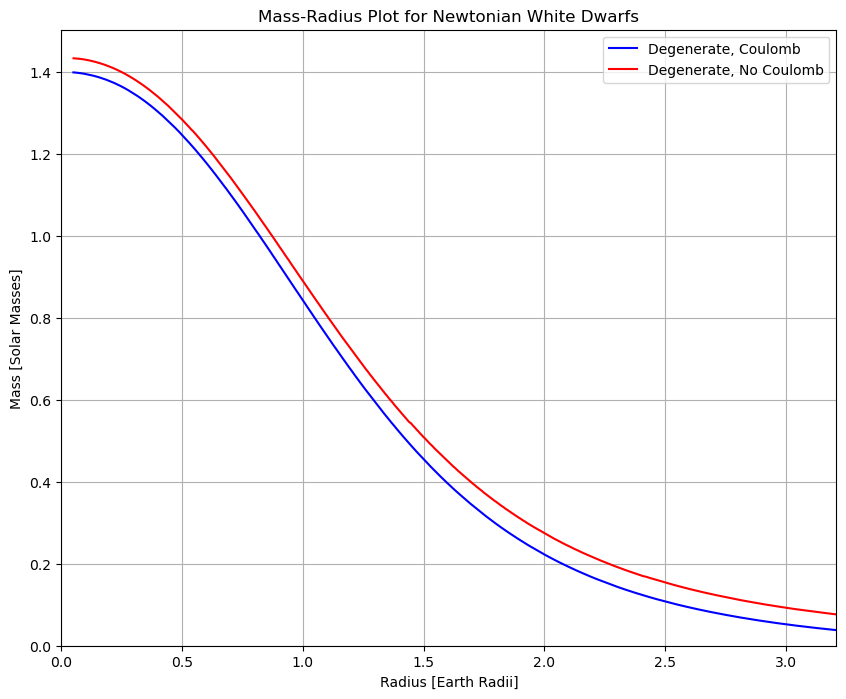

In [65]:
Z = (1/12 + 1/16)**(-1)
K = -3/10 * (4 * np.pi/3)**(1/3) * k_e * Z**(2/3) * q**2/(Mp * mu_e)**(4/3) 

@njit

def newt_WD_col(r, w):
    x, m = w
    rho = mu_e * B * x**3
    dxdr = - G * m * rho/r**2 * ((8 * A * x**4)/(1 + x**2)**(1/2) + 4 * K * (mu_e * B)**(4/3) * x**3)**(-1)
    dmdr = 4 * np.pi * rho * r**2
    return [dxdr, dmdr]

r_span = (0.001, 4*Re)
r_eval = np.linspace(0.001, 4*Re, 10**4)

def surface_r(r, w):
        x = w[0] 
        return x 

surface_r.terminal = True 
surface_r.direction = -1

def MR_relation_NWD_c():
    M_newtWD_c = []
    R_newtWD_c = []
    r1 = 0.001
    x1_arr = xc_arr - (2 * np.pi * G * rho_arr**2)/3 * ((8 * A * xc_arr**4)/(1 + xc_arr**2)**(1/2) + 4 * K * (mu_e * B)**(4/3) * xc_arr**3)**(-1) * r1**2
    m1_arr = 4 * np.pi * rho_arr * r1**3/3
    for i in range(len(rho_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol = solve_ivp(newt_WD_col, r_span, y0, events=surface_r, t_eval=r_eval, method='Radau')
        R = sol.t[-1]
        M = sol.y[1][-1]
        M_newtWD_c.append(M/Msol)
        R_newtWD_c.append(R/Re)
    return [R_newtWD_c, M_newtWD_c]

R_NWD_c, M_NWD_c = MR_relation_NWD_c()


plt.figure(figsize=(10,8))
plt.plot(R_NWD_c, M_NWD_c, color='blue', label='Degenerate, Coulomb')
plt.plot(R_NWD, M_NWD, color='red', label='Degenerate, No Coulomb')
plt.title('Mass-Radius Plot for Newtonian White Dwarfs')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD_c))
plt.ylim(bottom=0)
plt.legend()
plt.grid()

A noticeable decrease in the mass is observed for a given radius, also reducing the chandrasekhar mass closer to $\approx 1.4 M_{\odot}$.

### **General Relativistic Treatment**

Incorporating general relativity does not result in a significant change to a white dwarf's structure as we can see by computing the ratio of the radius with the Schwarzchild radius of the star.

For a typical mass of $~1M_{\odot}$ and radius of 7000km, the ratio of the radius to the Schwarzchild radius is 

$$ \frac{R}{R_s} = \frac{7000 \times 10^3}{(\frac{2 \times 6.67 \times 10^{-11} \times 1.989 \times 10^{30}}{(3 \times 10^8)^2})} =  2374 >> 1 $$

Showing that relativistic are not of significant effect in white dwarfs generally but plays a substantial role for higher density white dwarfs as we shall soon see.

Hydrostatic equilibrium of a non-rotating sphere in the Schwarzchild metric is governed by the Tolman Oppenheimer Volkoff Equation relating the pressure $P$ to density $\rho$, mass enclosed $m$ and radius $r$:

$$ \frac{dP}{dr} = - \frac{Gm \rho}{r^2} \left(1+\frac{P}{\rho c^2}\right) \left(1+\frac{4 \pi r^3 P}{m c^2}\right) \left(1-\frac{2Gm}{rc^2}\right)^{-1} $$

The mass enclosed $m$ at radius r is expressed in the ODE,

$$ \frac{dm}{dr} = 4 \pi r^2 \rho $$

With the initial conditions,

$$P(0) = P_c \hspace{1cm}  m(0) = 0 \hspace{1cm}  P'(0) = 0 $$

Which ensures a vanishing of the pressure gradient at a central pressure $P_c$ and zero mass at the origin.

In order to numerically integrate the ODEs, the pressure $P$ and density $\rho$ are parametrized in $x$ where $x(r)$ and $m(r)$ are functions to be determined which is identical to what we have done in the previous section where the chain rule is used.

$$ \frac{dx}{dr} = \frac{dP}{dr} \left(\frac{dP}{dx} \right)^{-1} $$

Where $\frac{dP}{dx}$ is upon evaluating the derivative,


$$ \frac{dP}{dx} = \frac{8 A x^4}{(1 + x^2)^{1/2}} $$

Then we can deduce $x'(0) = 0$.

The singularity at $r=0$ prompts a taylor series expansion around a point close to the origin. We know $P'(0)=0$ then we can take the second derivative of $x(r)$ and plug our BCs. We apply the definition of the derivative like before,

$$ x''(0) = \lim_{r \to 0} \frac{1}{r} \frac{dP}{dr} \left(\frac{dP}{dx} \right)^{-1}$$

Another trick is that $m(r) \approx \frac{4 \pi \rho_c r^3}{3}$ close to the origin and we also know that $\frac{dP}{dr} \propto \frac{m}{r^2}$. Then plugging the $m(r)$ cancels the $\frac{1}{r^3}$ term in $x''(0)$. It also eliminates the \frac{1}{r^3} in the brackets inside the TOV equation. 

However, we also need to deal with the $\left(1 - \frac{2Gm(r)}{r c^2}\right)^{-1}$ term which we can handle easily using L'Hopital's Rule (since both $m(r)$ and $r$ tend to zero at r=0),

$$\lim_{r \to 0} \frac{m(r)}{r} = \lim_{r \to 0} m'(r) = 4 \pi \rho_c \lim_{r \to 0} r^2 = 0$$

Hence the taylor series expansions are,

$$ x(r) \approx x_c - \frac{2 \pi G \rho_c^2}{3} \left(1 + \frac{P_c}{\rho_c c^2}\right) \left(1 + \frac{3 P_c}{c^2}\right) \frac{\sqrt{1 + x_c^2}}{8 A x_c^4} r^2 $$

$$ m(r) = \frac{4 \pi \rho_c r^3}{3} + ...$$

Then we can define our ODE system and use solve_ivp as the integrator.

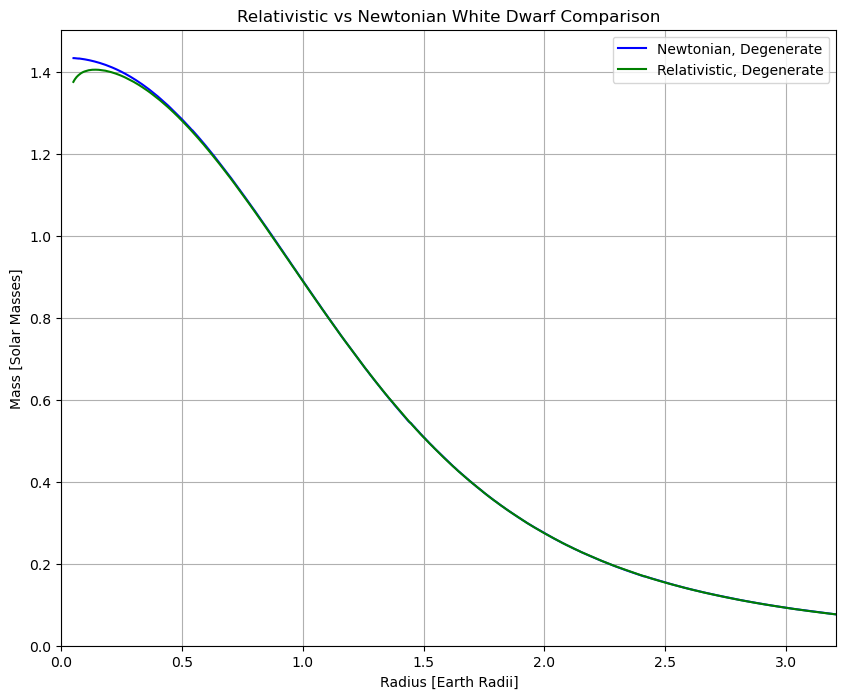

In [66]:
@njit
def GR_WD(r, w):
    x, m = w
    rho = mu_e * B * x**3
    P = A * (x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x))
    dxdr = - (G * m * rho)/r**2 * (1 + P/(rho * c**2)) * (1 + 4 * np.pi * r**3 * P/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (1 + x**2)**(1/2)/(8 * A * x**4)    
    dmdr = 4 * np.pi * r**2 * rho
    return [dxdr, dmdr]

def MR_relation_GRWD():
    M_genrelWD = []
    R_genrelWD = []
    Pc_arr = A * (xc_arr * (2 * xc_arr**2 - 3) * (1 + xc_arr**2)**(1/2) + 3 * np.arcsinh(xc_arr))
    r1 = 0.001
    x1_arr = xc_arr - (2 * np.pi * G * rho_arr**2)/3 * (1 + Pc_arr/(rho_arr * c**2)) * (1 + 3 * Pc_arr/c**2) * (1 + xc_arr**2)**(1/2)/(8 * A * xc_arr**4) * r1**2
    m1_arr = 4 * np.pi * rho_arr * r1**3/3
    for i in range(len(rho_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol = solve_ivp(GR_WD, r_span, y0, events=surface_r, t_eval=r_eval, method='Radau')
        R = sol.t[-1]
        M = sol.y[1][-1]
        M_genrelWD.append(M/Msol)
        R_genrelWD.append(R/Re)
    return [R_genrelWD, M_genrelWD]


R_GRWD, M_GRWD = MR_relation_GRWD()

plt.figure(figsize=(10,8))
plt.plot(R_NWD, M_NWD, color='blue', label = 'Newtonian, Degenerate')
plt.plot(R_GRWD, M_GRWD, color = 'green', label = 'Relativistic, Degenerate')
plt.title('Relativistic vs Newtonian White Dwarf Comparison')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD_c))
plt.ylim(bottom=0)
plt.legend()
plt.grid()

The mass radius curve peaks at around $\approx 1.4M_{\odot}$ which was unseen in the newtonian case. This denotes the maximum mass possible for our white dwarf called the Chandrasekhar limit. What is intriguing is that the limit was only uncovered using a fully general relativistic treatment of the star. 

In [67]:
M_GRWD_max = max(M_GRWD)
print('Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf:', round(M_GRWD_max,4), 'Msol')

Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf: 1.4058 Msol


Then the minimum radius and the central density at which the Chandrasekhar limit is reached can be determined.

In [68]:
R_GRWD_min = R_GRWD[M_GRWD.index(M_GRWD_max)] * Re/10**3 #Found index of maximum mass then use that same index to find the minimum radius possible. Note that it's an approximation rather than an interpolation.
print('Minimum radius of a relativistic, electron-degenerate carbon-oxygen white dwarf:', round(R_GRWD_min, 2), 'km')

rho_max = rho_arr[M_GRWD.index(M_GRWD_max)]
print('Maximum central density of a relativistic, electron-degenerate carbon-oxygen white dwarf:', round(rho_max/10**13, 4), r'x 10^13 kg/m3')

Minimum radius of a relativistic, electron-degenerate carbon-oxygen white dwarf: 890.46 km
Maximum central density of a relativistic, electron-degenerate carbon-oxygen white dwarf: 3.6861 x 10^13 kg/m3


The coloumb case proceeds exactly as before with the addition of a coloumb pressure term that alters $\frac{dP}{dx}$ in both the equations and the taylor series expansion. The plot summarizing the MR curves of all the white dwarf cases discussed as of right now has been shown.

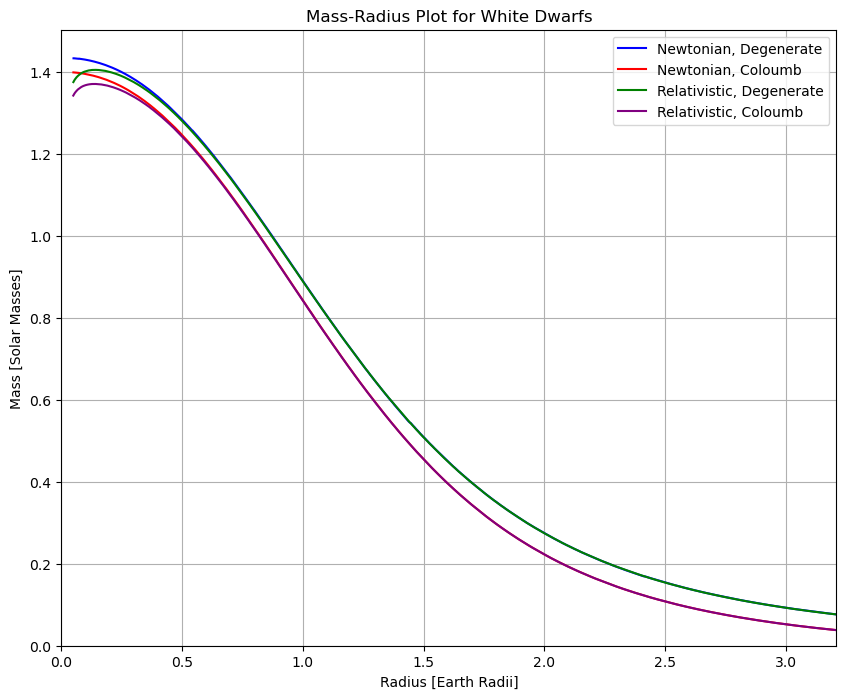

In [69]:
@njit

def GR_WD_c(r, w):
    x, m = w
    rho = mu_e * B * x**3
    P = A * (x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x)) + K * (mu_e * B)**(4/3) * x**4
    dxdr = - (G * m * rho)/r**2 * (1 + P/(rho * c**2)) * (1 + 4 * np.pi * r**3 * P/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (8 * A * x**4/(1 + x**2)**(1/2) + 4 * K * (mu_e * B)**(4/3) * x**3)**(-1)
    dmdr = 4 * np.pi * r**2 * rho
    return [dxdr, dmdr]

def MR_relation_GRWD_c():
    M_genrelWD_c = []
    R_genrelWD_c = []
    Pc_arr = A * (xc_arr * (2 * xc_arr**2 - 3) * (1 + xc_arr**2)**(1/2) + 3 * np.arcsinh(xc_arr)) + K * (mu_e * B)**(4/3) * xc_arr**4
    r1 = 0.001
    x1_arr = xc_arr - (2 * np.pi * G * rho_arr**2)/3 * (1 + Pc_arr/(rho_arr * c**2)) * (1 + 3 * Pc_arr/c**2) * (8 * A * xc_arr**4/(1 + xc_arr**2)**(1/2) + 4 * K * (mu_e * B)**(4/3) * xc_arr**3)**(-1) * r1**2
    m1_arr = 4 * np.pi * rho_arr * r1**3/3
    for i in range(len(rho_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol = solve_ivp(GR_WD_c, r_span, y0, events=surface_r, t_eval=r_eval, method='Radau')
        R = sol.t[-1]
        M = sol.y[1][-1]
        M_genrelWD_c.append(M/Msol)
        R_genrelWD_c.append(R/Re)
    return [R_genrelWD_c, M_genrelWD_c]

R_GRWD_c, M_GRWD_c = MR_relation_GRWD_c()

plt.figure(figsize=(10,8))
plt.plot(R_NWD, M_NWD, color='blue', label = 'Newtonian, Degenerate')
plt.plot(R_NWD_c, M_NWD_c, color='red', label = 'Newtonian, Coloumb')
plt.plot(R_GRWD, M_GRWD, color = 'green', label = 'Relativistic, Degenerate')
plt.plot(R_GRWD_c, M_GRWD_c, color = 'purple', label = 'Relativistic, Coloumb')
plt.title('Mass-Radius Plot for White Dwarfs')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD_c))
plt.ylim(bottom=0)
plt.legend()
plt.grid()



As expected, the coloumb correction softens the curve and reduces the Chandrasekhar limit.

In [70]:
M_GRWD_c_max = max(M_GRWD_c)
print('Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections:', round(M_GRWD_c_max,4), 'Msol')

Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections: 1.3714 Msol


In [71]:
R_GRWD_c_min = R_GRWD_c[M_GRWD_c.index(M_GRWD_c_max)] * Re/10**3
print('Minimum radius of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections:', round(R_GRWD_min, 2), 'km')

rho_max = rho_arr[M_GRWD_c.index(M_GRWD_c_max)]
print('Maximum central density of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections:', round(rho_max/10**13, 4), 'x 10^13 kg/m3')

Minimum radius of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections: 890.46 km
Maximum central density of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections: 3.7547 x 10^13 kg/m3


### **Finite Temperature Correction with a Non-Degenerate Surface Layer**

White dwarfs have in reality have a non-zero temperature due to the luminosity radiating energy away, an effect we ignored previously since in practice the temperatures lie well below the fermi temperature. We can determine the fermi temperature by the following relation. 

$$ T_F = \frac{1}{k_b} E_F = \frac{1}{k_B} m_e c^2 \sqrt{x^2 +1} \hspace{5mm} \text{where} \hspace{5mm} x = \left(\frac{\rho}{\mu_e B} \right)^{1/3}
$$

For some typical value of density $\sim 10^9 kg/m^3$, we have $T_F \approx 7.6 \times 10^9 K$. The fermi temperature is extremely high and only close to that limit do we have to take into account, a finite temperature correction to the electron degenerate gas which is more applicable to hotter and younger white dwarfs.

The density of the white dwarf decreases monotonically from its center to its surface as electron degenerate matter. At some point close to its surface, it ceases to be degenerate and now behaves like a regular gas. We can then treat our star being separated into two distinct layers, a degenerate core and a non-degenerate surface layer. 

As shown in Theoretical Astrophysics Vol 1, the thermal conductivity of electron degenerate gas is substantially high which causes heat to diffuse very quickly throughout the core at a timescale of $\sim 10^6$ years. The heat is distributed equally all throughout the core hence the core can be taken to be isothermal. This adds to a correction terms to both the number density and pressure as shown in Vol 1 with a Sommerfeld expansion,

$$ n = \frac{8 \pi}{3} \left(\frac{h}{m_e c}\right)^{-3} \left(x^3 + \pi^2 \frac{(1+2x^2)}{2x^3} \frac{1}{q^2} + \dots \right)$$

$$ P = \frac{\pi}{3} \left(\frac{h}{mc} \right)^{-3} \left(F(x) + 4 \pi^2 x(1+x^2)^{1/2} \frac{1}{q^2} + \dots \right) $$


where $q \equiv \frac{1}{k_B T}$ and $F(x) = x(x^2+1)^{1/2}(2x^2-3)+3\sinh^{-1}(x)$

The rest of the method used before works however, we need to compute the derivative $\frac{dP}{dx}$ for the equations of structure. Instead of computing by hand, it can be done symbolically using the package SymPy to calculate both the functions and derivatives. Then sp.lambdify converts the expressions into functions that returns values. 

These functions $P(x, T), \rho(x,T)$ and derivative $\frac{dP}{dx}(x,T)$ are finally used in our ODEs and taylor series expansions.

In [72]:
z, t = sp.symbols('z t')

def F(y):
    return y * (y**2 + 1)**(1/2) * (2 * y**2 - 3) + 3 * sp.asinh(y)

rho_expr = mu_e * B * z**3 * (1 + np.pi**2 * (1 + 2 * z**2) / (2 * z**4) * (k_b * t / (Me * c**2))**2)
P_expr = A * (F(z) + 4 * np.pi**2 * z * (1 + z**2)**(0.5) * (k_b * t / (Me * c**2))**2) + K * (rho_expr)**sp.Rational(4,3) #The coloumb correction term has also been added
dPdx_expr = P_expr.diff(z, 1)

compute_P = sp.lambdify((z, t), P_expr, 'numpy')
compute_rho = sp.lambdify((z, t), rho_expr, 'numpy')
compute_dPdx = sp.lambdify((z, t), dPdx_expr, 'numpy')


def P(y, T): 
    return compute_P(y, T)


def rho(y, T): 
    return compute_rho(y, T)


def dPdx(y, T): 
    return compute_dPdx(y, T)


Now for the surface envelope, we have assumed a bound free opacity $\kappa \propto \rho T^{-3.5}$ and an ideal gas from Theoretical Astrophysics Vol2 which leads to a polytrope relation between pressure and density, $P \propto \rho^{17/13}$. This will be our equation of state which used in the TOV equation for the envelope.

The boundary between which we stop integrating for the core and start integrating for the envelope until we find the surface needs to be determined. A criterion we use is the following, at some transition radius $r_0$, the Fermi energy plus coloumb energy per electron ($E_c/Z$) equals the thermal energy ($k_B T$).

$$m_e c^2 \sqrt{x^2+1} + \frac{E_c}{Z} = k_B T $$

where $E_c \propto \rho^{1/3}$ determined in the section on the coloumb correction term. We can then find x using a root-finding algorithm where brenteq has been chosen.

The event at which the $x(r)=x(r_0)$ is identified and the integration of the envelope ODEs starts from there until the surface is reached and finally both mass and radius are determined.

Now we can proceed with generating the MR curve in this case keeping in mind there are two systems of differential equations need to be solved for the two layers. The temperature chosen is $5 \times 10^7 K$ which is closer to the fermi temperature.

In [ ]:
x_arr = np.linspace(0.5, 50, 10**3)
D = -9/10 * (4 * np.pi/3)**(1/3) * k_e * Z**(2/3) * q**2

def GR_WD_T(r, w, T0):  #ODE system for the electron degenerate, isothermal core
    x, m = w
    dxdr = - (G * m * rho(x, T0))/r**2 * (1 + P(x, T0)/(rho(x, T0) * c**2)) * (1 + 4 * np.pi * r**3 * P(x, T0)/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (dPdx(x, T0))**(-1)
    dmdr = 4 * np.pi * r**2 * rho(x, T0)
    return [dxdr, dmdr]

def WD_env(r, w, C):   #Separate ODE system for the envelope is defined
    rho, m = w
    drhodr = - (13 * G * m * rho**(9/13))/(17 * C * r**2) * (1 + C * rho**(4/13)/c**2) * (1 + 4 * np.pi * r**3 * C * rho**(17/13)/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1)
    dmdr = 4 * np.pi * rho * r**2          #Uses the TOV equation but substitutes the polytropic form between pressure and density
    return [drhodr, dmdr]

def core_boundary(T0):
    def core_eq(x):
        E_F = Me * c**2 * (np.sqrt(x**2 + 1) -1)
        E_c = D * (rho(x, T0)/(mu_e * Mp))**(1/3)
        return E_F + E_c - k_b * T0
    root = brentq(core_eq, 0.01, 0.5)
    return root

def core(r, w, T0):
    x = w[0]
    return x - core_boundary(T0)  #Cuts integration at x(r0) when it transitions to non degenerate matter

core.terminal = True

def envelope(r, w, C):
    rho = w[0]
    return rho - 1e-3

envelope.terminal = True 
envelope.direction = -1


def MR_relation_T(T0):
    M_GRWD_T = []
    R_GRWD_T = []

    Pc_arr = P(x_arr, T0)

    rhoc_arr = rho(x_arr, T0)

    dPdxc_arr = dPdx(x_arr, T0)

    r1 = 0.001

    x1_arr = x_arr - (2 * np.pi * G * rhoc_arr**2)/3 * (1 + Pc_arr/(rhoc_arr * c**2)) * (1 + 3 * Pc_arr/c**2) * (dPdxc_arr)**(-1) * r1**2

    m1_arr =  4 * np.pi * rhoc_arr * r1**3/3

    x0 = core_boundary(T0)

    P0 = P(x0, T0)
    rho0 = rho(x0, T0)
    C = P0/(rho0)**(17/13)

    for i in range(len(x_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol_core = solve_ivp(GR_WD_T, r_span, y0, events=core, args=(T0,), method='Radau', max_step=1e3)
        r0 = sol_core.t_events[0][0]
        m0 = sol_core.y_events[0][0][-1]
        env_span = (r0, 4*Re)
        sol_env = solve_ivp(WD_env, env_span, y0=[rho0, m0], events=envelope, args=(C,), method='Radau', max_step=1e4)
        
        M = sol_env.y_events[0][0][-1]
        R = sol_env.t_events[0][0]
        M_GRWD_T.append(M/Msol)
        R_GRWD_T.append(R/Re)
    return [R_GRWD_T, M_GRWD_T]


R_5e7, M_5e7 = MR_relation_T(5*10**7)

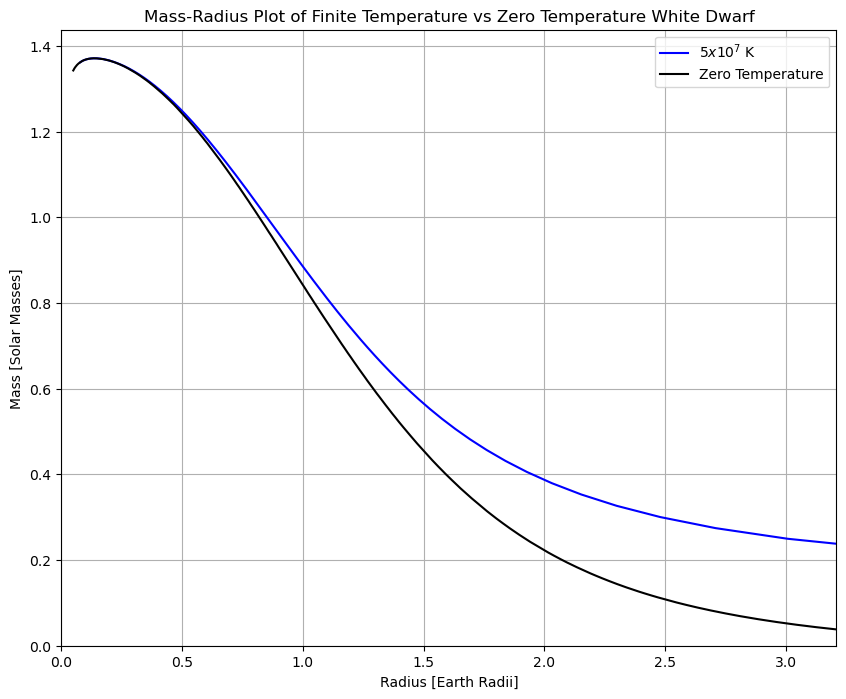

In [12]:
plt.figure(figsize=(10,8))
plt.plot(R_5e7, M_5e7, color = 'blue', label=r'$5x10^7$ K')
plt.plot(R_GRWD_c, M_GRWD_c, color='black', label='Zero Temperature')
plt.title('Mass-Radius Plot of Finite Temperature vs Zero Temperature White Dwarf')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_GRWD_c))
plt.ylim(bottom=0)
plt.grid()
plt.legend()
plt.show()

The resulting plot compares the MR curves between a zero-temperature white dwarf and $5 \times 10^7 K$ core temperature white dwarf. This shows the finite temperature white dwarf expanding in radius for a given mass which is most prominent for lower masses. The two curves converge to each other close to the Chandrasekhar limit indicating that dominant temperature correction terms are not significant for higher density stars.

### **Interpolating To Determine Masses and Radii**

Acquiring visual plots are highly valuable for deducing qualitative interpretations for how the star's mass and radius behave with respect to each other. Though it is not of much importance when attempting to make predictions given one variable or another. 

We can do this through the SciPy where CubicSpline is used to interpolate the curve and determine either mass or radius from each other. One hurdle is that the arrays are not sorted in ascending order or may have duplicates. The function np.unique sorts and removes duplicates for both arrays so the length remains the same and keeps the matching variables together. 

In [38]:
#A zero-temperature, general relativistic white dwarf with coloumb interactions is chosen here
R_arr = np.array(R_GRWD_c)
M_arr = np.array(M_GRWD_c)

R_arr, unique_idx = np.unique(R_arr, return_index=True)
M_arr = M_arr[unique_idx]  #Same unique indices are used here so the numbers match and also keeps length of both arrays the same

cs = CubicSpline(R_arr,M_arr)
print('Mass of a 1 Earth Radius White Dwarf:', round(float(cs(1)), 3), 'Msol')

Mass of a 1 Earth Radius White Dwarf: 0.842 Msol


### **Nuclear Equation Of State For White Dwarfs Near Critical Density**

For the interior structure of white dwarfs covered until now, we have treated the system as consisting of electron degenerate gas which is valid for densities greater than $10^9 \hspace{1mm} \text{kg/m}^3$. Densities far below this value exhibits non-relativistic behavior for the electrons and solid lattice of positive ions.

As density increases, the Fermi energy of electrons increases to the point where neutronisation can be caused resulting in an inverse beta decay reaction. The electrons combine with protons in the nuclei releasing neutrons and neutrinos.

This changes the atomic number $Z$ and the mass number $A$ and such transformation of the nuclei would require find a stable configuration.

The increasing coloumb repulsion between protons has to be balanced by the increased attractive nuclear force between neutrons where the lowest energy state is Iron-56. However, the formation of neutrons from inverse beta decay makes it favourable to form nuclei with $A>>56$. But above a density of $4 \times 10^{14} \hspace{1mm} \text{kg/m}^{-3}$, neutrons begin to leak out of the nuclei called free neutrons. This is above the density at Chandrasekhar density (See section on GR Coloumb Case) and will not concern us right now.

The energy density of the nuclei, free electrons and free neutrons is written as,

$$\epsilon = n_N M(A,Z) + \epsilon'_e(n_e) + \epsilon_n(n_n) + \epsilon_c(n_e)$$

The subscripts N refers to nucleons, e to electrons (no rest energy) and n to neutrons and $M(A,Z)$ is the energy of the atom with atomic and mass numbers Z, A (including the rest energy of $Z$ electrons).

$$M(A, Z) = (A-Z)m_n c^2 + Z(m_p + m_e)c^2 - E_B$$

and using the liquid drop model,

$$ E_B = a_V A - a_S A^{2/3} - a_C \frac{Z(Z-1)}{A^{1/3}} - a_A \frac{(A-2Z)^2}{A} + \delta
$$

where 

$$\delta = 
\begin{cases}
    +\Delta & \text{for even-even nuclei} \\
    0 & \text{for odd A (odd-even, even-odd)} \\
    - \Delta & \text{for odd-odd nuclei}
\end{cases}
$$

The term $\epsilon_c$ is the coloumb energy density calculated by $E_C/V = 3E_c/(4 \pi r_0^3)$ ($r_0$ is radius of the cell).

Explicitly it's,

$$\epsilon_C (n_e) = - \frac{27}{40} \frac{k Z^2 e^2}{\pi} \left(\frac{4 \pi}{3 Z}  \right)^{4/3} n_e^{4/3} $$

We define the baryon number density $n=n_N A + n_n$ and the neutron fraction $Y_n \equiv n_n/n$ in order to express the energy,

$$\epsilon = n(1 - Y_n)\frac{M(A,Z)}{A} + \epsilon'_e(n_e) + \epsilon_n(n_n)$$

$$ n_e = n(1 - Y)\frac{Z}{A} $$

$$n_n = n Y_n$$

To find the equilibrium configuration, we must minimize $\epsilon(n, A, Z, Y_n)$ with respect to $A, Z,$ and $Y_n$ at constant $n$. The pairing term $\delta$ is neglected for simplicity.

The lengthy derivation is included in the scratchwork folder but a key step is remembering the thermodynamic relation and the fact that the chemical potential is the Fermi energy,

$$\frac{\partial \epsilon_e}{\partial n_e} = \mu_e = E_F = m_e c^2 \sqrt{x_e^2 +1}$$

The resulting equations relating $A, Z, x_e$ and $x_n$ are,

$$A \frac{\partial M(A,Z)}{\partial A}- M(A,Z) - Zm_e c^2(\sqrt{x_e^2+1}-1) + \frac{9}{10} \frac{k Z^{5/3} e^2}{\pi} \left(\frac{4 \pi}{3} \right)^{4/3} \left(\frac{8 \pi}{3} \right)^{1/3} \frac{m_e c}{h} x_e = 0 $$

$$Z = \sqrt{\frac{a_S}{2 a_C}} A^{1/2} $$

$$ \frac{\partial M(A,Z)}{\partial A} = m_n c^2 \sqrt{1+x_n^2} $$

The plan here is to calculate the $Z, A$ of the equilibrium configuration from the given $x_e$ where we can use the x_arr to calculate nuclear parameters over the range in $x_e$. We treat $Z$ and $A$ as continuous functions but we round them to the nearest integers and finally stop at the point where neutron drip is reached $x_n>0$. Then our energy density can be calculated with varying $Z,A$ as,

$$\rho = \frac{n_e\frac{M(A,Z)}{Z} + \epsilon_e'}{c^2} $$

This is the mass density that takes into account all energies of the system instead of only the rest mass as we have done before. We can now compute the $Z$ and $A$ by using a root-finding algorithm (brentq). But first, let's define the necessary constants for the nuclear physics involved,

In [4]:
mp = 1.673 * 10**-27
me = 9.109 * 10**-31
mn = 1.675 * 10**-27
rn = 1.2 * 10**-15   #Proportionality constant for the nuclear radius
e = 1.602 * 10**-19

#Liquid drop model parameters
aV = 15.8 * 10**6 * e
aA = 18.3 * 10**6 * e
aS = 23.3 * 10**6 * e
aC = (3/5) * (k_e * e**2)/rn

In [5]:
def ZA(arr):
    Z_list = []
    A_list = []
    
    for i in range(len(arr)):
        def minimize(Z):
                A = 2 * aC/aS * Z**2
                EB = aV * A - aS * A**(2/3) -aC * Z*(Z-1)/A**(1/3) -aA * ((A-2*Z)**2)/A
                M = (A - Z) * mn * c**2 + Z * (mp + me) * c**2 - EB
                dMdA = mn * c**2 - aV + 2/3 * aS * A**(-1/3) - aC/3 * Z*(Z-1)*A**(-4/3) + aA *(A-2*Z)*(3*A-2*Z)/A**2
                f = A * dMdA - M - Z * me * c**2 * (np.sqrt(arr[i]**2 + 1) -1) + 9/10 * (k_e * Z**(5/3) * e**2)/np.pi * (4 * np.pi/3)**(4/3) * (8 * np.pi/3)**(1/3) * (me * c/h) * arr[i]
                return f

        Z = round(brentq(minimize, 1, 100))
        A = 2 * aC/aS * Z**2
        Z_list.append(Z)
        A_list.append(round(A))
        dMdA = mn * c**2 - aV + 2/3 * aS * A**(-1/3) - aC/3 * Z*(Z-1)*A**(-4/3) + aA *(A-2*Z)*(3*A-2*Z)/A**2
        x_n = np.sqrt(1/(mn*c**2)**2 * (dMdA)**2 - 1)

        if x_n>0:
            break    #breaks the loop when neutron drip is reached (x_n>0)

    return [Z_list, A_list]


In [6]:
Z_list, A_list = ZA(xc_arr)

print('The most stable nucleus with the lowest Z of', min(Z_list), 'and has A of', min(A_list))
print('Most stable nucleus at which neutron drip is reached has atomic number', max(Z_list), 'and mass number', max(A_list))


The most stable nucleus with the lowest Z of 37 and has A of 85
Most stable nucleus at which neutron drip is reached has atomic number 48 and mass number 142


The nuclei with $Z=37$ corresponds to the element Rubidium and $Z=48$ is the element Cadmium but with mass number of 142 which is higher than the most common isotope with $A=112$.

Using xc_arr, Z_list and A_list, we can construct functions that predict $Z, A$ for a given x by using a cubic spline. Plotting list of $Z$ and $A$ values directly, we observe atomic and mass numbers increase in discrete steps as integers.

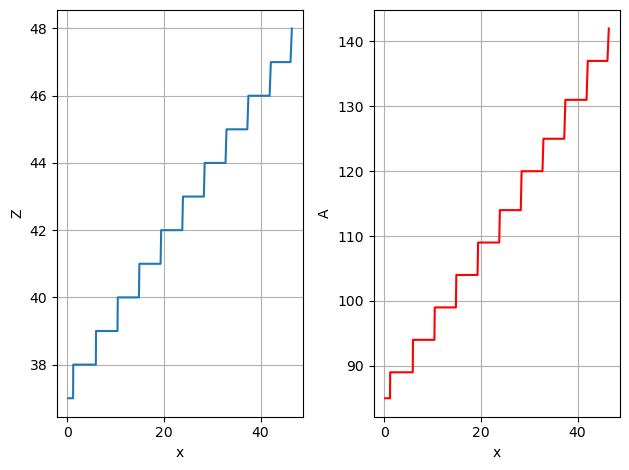

In [7]:
plt.subplot(1,2,1)
plt.plot(xc_arr[:len(Z_list)], Z_list)
plt.xlabel('x')
plt.ylabel('Z')
plt.grid()

plt.subplot(1,2,2)
plt.plot(xc_arr[:len(A_list)], A_list, color='red')
plt.xlabel('x')
plt.ylabel('A')
plt.grid()
plt.tight_layout()

In [8]:
def Z(x):
    rho_arr = np.logspace(7, 15, 10**3)   
    xc_arr = (rho_arr/(mu_e * B))**(1/3)
    xc_arr = xc_arr[:len(Z_list)]  #so xc_arr has the same length as Z_list (remember that the loop breaks when neutron drip is reached at a certain value of x)
    cs = CubicSpline(xc_arr, Z_list)
    return np.round(cs(x))

def A(x):
    rho_arr = np.logspace(7, 15, 10**3)   
    xc_arr = (rho_arr/(mu_e * B))**(1/3)
    xc_arr = xc_arr[:len(A_list)]
    cs = CubicSpline(xc_arr, A_list)
    return np.round(cs(x))

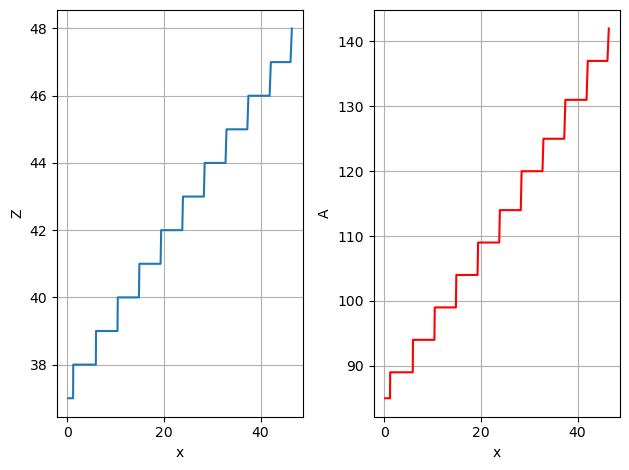

In [9]:
plt.subplot(1,2,1)
plt.plot(xc_arr[:len(Z_list)], Z(xc_arr[:len(Z_list)]))
plt.xlabel('x')
plt.ylabel('Z')
plt.grid()

plt.subplot(1,2,2)
plt.plot(xc_arr[:len(A_list)], A(xc_arr[:len(Z_list)]), color='red')
plt.xlabel('x')
plt.ylabel('A')
plt.grid()
plt.tight_layout()

The plots of the function match exactly the values of $Z$ and $A$ calculated.

We can then form an Equation of State between $P$ and $\rho$ implicitly through the parametrized variable $x_e$. This involves using the equations stated above where we need the energy density of the degenerate electrons excluding the rest mass $\epsilon'(n_e)$ which is calculated by (derived in Theoretical Astrophysics Vol 1, Chap 5),

$$
F(x) = x (2x^2 - 3)\sqrt{1 + x^2} + 3 \sinh^{-1}(x) \\
\epsilon'(n_e) = \frac{1}{24\pi^2} \left(\frac{\hbar}{m_e c}\right)^{-3} (m_e c^2) \left(8x^3 \left(\sqrt{1+x^2} - 1\right) - F(x) \right)
$$

Below a certain density (at $1.9 \times 10^{13}\hspace{1mm} \text{kg/m}^3$ for Oxygen-16), neutronisation is not possible so relativistic energy degenerate matter is only possible. Hence, we can take the average nuclear charge and average atomic numbers, $\bar{Z}$ and $\bar{A}$ of carbon-oxygen (50-50 mass split) substituted into these formulas less than $1.9 \times 10^{13}\hspace{1mm} \text{kg/m}^3$. Also a function has been defined below to take into account the pairing term in the Liquid Drop Model which is tehn used in our Equation of State.



In [29]:
ap = 33 * 10**6 * e  

def delta(m, n):  #Z, A     
    k = n - m    #N = A - Z
    m_arr = np.array(m)
    n_arr = np.array(n)
    k_arr = np.array(k) 

    even_even = (m_arr%2==0) & (k_arr%2==0)
    even_even_arr = np.where(even_even==True, ap * n**(-3/4), 0)

    odd_odd = (m_arr%2!=0) & (k_arr%2!=0)
    odd_odd_arr = np.where(odd_odd==True, -ap * n**(-3/4), 0)

    oddA = (n_arr%2!=0)
    oddA_arr = np.where(oddA==True, 0, 0)

    delta_arr = even_even_arr + odd_odd_arr + oddA_arr
    return delta_arr


def rho_EOS(x):
    x0 = ((1.9*10**13)/(mu_e * B))**(1/3)     #x value below which there is no inverse beta decay
    n_e = (B/mp) * x**3
    EB = aV * A(x) - aS * A(x)**(2/3) -aC * Z(x)*(Z(x)-1)/A(x)**(1/3) -aA * ((A(x)-2*Z(x))**2)/A(x) + delta(Z(x), A(x))
    M = (A(x) - Z(x)) * mn * c**2 + Z(x) * (mp + me) * c**2 - EB
    F = x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x)
    epsilon = (1/(24 * np.pi**2)) * (hbar/(me * c))**(-3) * (me * c**2) * (8 * x**3 * ((1+x**2)**(1/2) -1) - F)
    epsilon_c = -27/40 * (k_e * Z(x)**2 * e**2)/np.pi * (4 * np.pi/(3 *Z(x)))**(4/3) * n_e**(4/3)
    mass_density = 1/c**2 * (n_e * M/Z(x) + epsilon + epsilon_c)

    Zbar = (1/12 + 1/16)**(-1)
    Abar = 2 * Zbar       #by using the same analysis as in the newtonian, coloumb section
    EB_else = aV * Abar - aS * Abar**(2/3) -aC * Zbar*(Zbar-1)/Abar**(1/3) -aA * ((Abar-2*Zbar)**2)/Abar + delta(Zbar, Abar)
    M_else = (Abar - Zbar) * mn * c**2 + Zbar * (mp + me) * c**2 - EB_else
    epsilon_c_else = -27/40 * (k_e * Zbar**2 * e**2)/np.pi * (4 * np.pi/(3 *Zbar))**(4/3) * n_e**(4/3)
    mass_density_else = 1/c**2 * (n_e * M_else/Zbar + epsilon + epsilon_c_else)
    
    return np.where(x >= x0, mass_density, mass_density_else)   #Creates an array where the pressure switches if x<x0


def P_EOS(x):
    x0 = ((1.9*10**13)/(mu_e * B))**(1/3) 
    Zbar = (1/12 + 1/16)**(-1)
    mu = A(x)/Z(x)
    K = -3/10 * (4 * np.pi/3)**(1/3) * k_e * Z(x)**(2/3) * e**2/(mp * mu)**(4/3) 
    A_cnst = np.pi/3 * (h/(me * c))**(-3) * me * c**2
    B_cnst = 8 * np.pi * mp/3 * (h/(me * c))**(-3)
    P = A_cnst * (x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x)) + K * (mu * B_cnst)**(4/3) * x**4

    K_else = -3/10 * (4 * np.pi/3)**(1/3) * k_e * Zbar**(2/3) * e**2/(mp * mu_e)**(4/3) 
    P_else = A_cnst * (x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x)) + K_else * (mu_e * B_cnst)**(4/3) * x**4

    return np.where(x >= x0, P, P_else)
    

Note that the mean molecular weight of electrons $\mu$ has been altered from $\mu_e \approx 2$ for the equilibrium configuration nuclei. By using the formula $\mu = A/Z$ (Theoretical Astrophysics Chap 5 Page 206) and the assumption that the region in the star is dominated by $(Z,A)$ nuclei. 

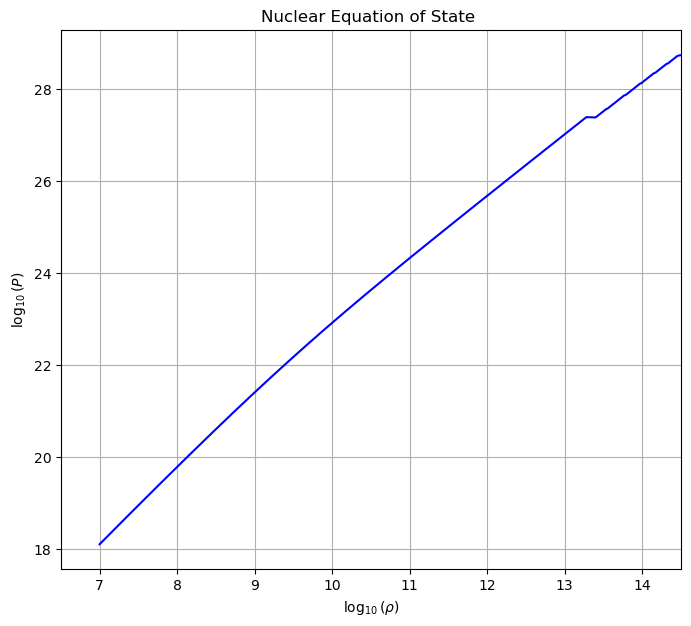

In [30]:
plt.figure(figsize=(8,7))
plt.plot(np.log10(rho_EOS(xc_arr)), np.log10(P_EOS(xc_arr)), color='blue')
plt.xlabel(r'$\log_{10}(\rho)$')
plt.ylabel(r'$\log_{10}(P)$')
plt.xlim(6.5, 14.5)
plt.title('Nuclear Equation of State ')
plt.grid()

The resulting plot shows a rapid increase of pressure and density by orders of magnitude with a few bumps in the pressure. This could point towards phase transitions in how nuclei begin to transform due to inverse beta decay. The region at $ \log_{10}(\rho) \approx 15$ has been neglected since neutron drip plays a substantial role which is neglected in our analysis. This heads into neutron star crust territory and is not of our concern here. 

### **Mass-Radius Curve with a Nuclear Equation of State**

In [33]:
Zbar = (1/12 + 1/16)**(-1)
A_cnst = np.pi/3 * (h/(me * c))**(-3) * me * c**2
D = -9/10 * (4 * np.pi/3)**(1/3) * k_e * Zbar**(2/3) * e**2
Kbar = -3/10 * (4 * np.pi/3)**(1/3) * k_e * Zbar**(2/3) * e**2/(mp * mu_e)**(4/3) 

r_span = (0.001, 4*Re)
r_eval = np.linspace(0.001, 4*Re, 10**4)

z, t = sp.symbols('z t')

def F(y):
    return y * (y**2 + 1)**(1/2) * (2 * y**2 - 3) + 3 * sp.asinh(y)

rho_expr = mu_e * B * z**3 * (1 + np.pi**2 * (1 + 2 * z**2) / (2 * z**4) * (k_b * t / (Me * c**2))**2)
P_expr = A_cnst * (F(z) + 4 * np.pi**2 * z * (1 + z**2)**(0.5) * (k_b * t / (me * c**2))**2) + Kbar * (rho_expr)**sp.Rational(4,3) #The coloumb correction term has also been added
dPdx_expr = P_expr.diff(z, 1)

compute_P = sp.lambdify((z, t), P_expr, 'numpy')
compute_rho = sp.lambdify((z, t), rho_expr, 'numpy')
compute_dPdx = sp.lambdify((z, t), dPdx_expr, 'numpy')


def P(y, T): 
    return compute_P(y, T)


def rho(y, T): 
    return compute_rho(y, T)


def dPdx(y, T): 
    return compute_dPdx(y, T)


def GR_WD_nuc(r, w, T0=0):
    x, m = w
    x0 = ((1.9*10**13)/(mu_e * B))**(1/3) 
    if x>=x0:
        mu = A(x)/Z(x)
        rho_val = mu * B * x**3
        K = -3/10 * (4 * np.pi/3)**(1/3) * k_e * Z(x)**(2/3) * e**2/(mp * mu)**(4/3) 
        P_val = A_cnst * (x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x)) + K * (mu_e * B)**(4/3) * x**4  #Assumed zero temperature over here for simplicity for the minimization
        dxdr = - (G * m * rho_val)/r**2 * (1 + P_val/(rho_val * c**2)) * (1 + 4 * np.pi * r**3 * P_val/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (8 * A_cnst * x**4/(1 + x**2)**(1/2) + 4 * K * (mu_e * B)**(4/3) * x**3)**(-1)
        dmdr = 4 * np.pi * r**2 * rho_val
        return [dxdr, dmdr]
    
    elif x<x0:
        dxdr = - (G * m * rho(x, T0))/r**2 * (1 + P(x, T0)/(rho(x, T0) * c**2)) * (1 + 4 * np.pi * r**3 * P(x, T0)/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (dPdx(x, T0))**(-1)
        dmdr = 4 * np.pi * r**2 * rho(x, T0)
        return [dxdr, dmdr]


def WD_env(r, w, C):   
    rho_val, m = w
    drhodr = - (13 * G * m * rho_val**(9/13))/(17 * C * r**2) * (1 + C * rho_val**(4/13)/c**2) * (1 + 4 * np.pi * r**3 * C * rho_val**(17/13)/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1)
    dmdr = 4 * np.pi * rho_val * r**2          #Uses the TOV equation but substitutes the polytropic form between pressure and density
    return [drhodr, dmdr]

def core_boundary(T0):
    def core_eq(x):
        E_F = me * c**2 * (np.sqrt(x**2 + 1) -1)
        E_c = D * (rho(x, T0)/(mu_e * mp))**(1/3)
        return E_F + E_c - k_b * T0
    root = brentq(core_eq, 0.01, 0.5)
    return root

def core(r, w, T0):
    x = w[0]
    return x - core_boundary(T0)  #Cuts integration at x(r0) when it transitions to non degenerate matter

core.terminal = True

def envelope(r, w, C):
    rho_val = w[0]
    return rho_val - 1e-3

envelope.terminal = True 
envelope.direction = -1

In [ ]:
def MR_relation_GRWD_nuc(T0=0):

    M_GRWD_nuc = []
    R_GRWD_nuc = []

    Pc_arr = P_EOS(xc_arr)

    rhoc_arr = rho_EOS(xc_arr)

    mu_c = A(xc_arr)/Z(xc_arr)
    K0 = -3/10 * (4 * np.pi/3)**(1/3) * k_e * Z(xc_arr)**(2/3) * e**2/(mp * mu_c)**(4/3) 
    dPdxc_arr = (8 * A_cnst * xc_arr**4)/(1 + xc_arr**2)**(1/2) + 4 * K0 * (mu_c * B)**(4/3) * xc_arr**3

    r1 = 0.001

    x1_arr = xc_arr - (2 * np.pi * G * rhoc_arr**2)/3 * (1 + Pc_arr/(rhoc_arr * c**2)) * (1 + 3 * Pc_arr/c**2) * (dPdxc_arr)**(-1) * r1**2

    m1_arr =  4 * np.pi * rhoc_arr * r1**3/3

    x0 = core_boundary(T0)

    P0 = P(x0, T0)
    rho0 = rho(x0, T0)
    C = P0/(rho0)**(17/13)

    for i in range(len(xc_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol_core = solve_ivp(GR_WD_nuc, r_span, y0, events=core, args=(T0,), method='Radau', max_step=1e3)
        r0 = sol_core.t_events[0][0]
        m0 = sol_core.y_events[0][0][-1]
        env_span = (r0, 4*Re)
        sol_env = solve_ivp(WD_env, env_span, y0=[rho0, m0], events=envelope, args=(C,), method='Radau', max_step=1e4)
                
        M = sol_env.y_events[0][0][-1]
        R = sol_env.t_events[0][0]
        M_GRWD_nuc.append(M/Msol)
        R_GRWD_nuc.append(R/Re)
    return [R_GRWD_nuc, M_GRWD_nuc]

R_GRWD_Nuc, M_GRWD_Nuc = MR_relation_GRWD_nuc(0)